# LAB 08 - Pretrained Transformer: fine-tuning BERT-mini trên IMDb

- Model: `google/bert_uncased_L-4_H-256_A-4` (BERT-mini), tokenizer `bert-base-uncased`, load offline từ `../hf_models`.
- Dữ liệu IMDb, cùng split với LAB 04 - 07 (dùng lại `lab4/preprocessing.py`).
- Code model và vòng train ở `pretrained_classification.py`. Notebook ghi `results.csv` và các hình `.png`.

## 0. Setup và reproducibility

In [1]:
import os
import platform
import sys
import time

sys.path.insert(0, os.path.abspath("../lab4"))
from pretrained_classification import (MODEL_NAME, TOKENIZER_NAME, BertClassifier, encode, load_tokenizer,
                                       n_params, predict_logits, train)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, confusion_matrix,
                             f1_score, precision_score, recall_score)
from preprocessing import LABEL_NAMES, clean_text, deduplicate, load_imdb, remove_overlap, split_train_val

SEED = 42
QUICK = os.environ.get("LAB8_QUICK") == "1"
torch.set_num_threads(8)
torch.manual_seed(SEED)
pd.set_option("display.max_colwidth", 160)

MAX_LEN = 128
BATCH = 32
LR = 1e-4
EPOCHS = 2
FRACTIONS = [0.10, 0.25, 0.50, 1.0]
TEST_SUB = 500 if QUICK else 5000      # tập test con cố định cho các thí nghiệm ablation

RESULTS = []
def log(experiment, model, setting, split, metric, value):
    RESULTS.append({"experiment": experiment, "model": model, "setting": setting, "split": split, "metric": metric, "value": value})

def metrics(y, pred):
    return {"accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred, zero_division=0), "f1": f1_score(y, pred, zero_division=0)}

repro = {"Model": MODEL_NAME, "Tokenizer": TOKENIZER_NAME, "Dataset": "IMDb (stanfordnlp/imdb), dedup + bỏ trùng train/test",
         "Max sequence length": MAX_LEN, "Batch size": BATCH, "Learning rate": LR, "Epochs": EPOCHS,
         "Optimizer": "AdamW (weight decay 0.01), linear warmup 10% + decay, clip 1.0", "Random seed": SEED,
         "Hardware": f"CPU {platform.processor()}, {torch.get_num_threads()} threads, không GPU",
         "torch": torch.__version__}
pd.Series(repro)

Model                                                              google/bert_uncased_L-4_H-256_A-4
Tokenizer                                                                          bert-base-uncased
Dataset                                         IMDb (stanfordnlp/imdb), dedup + bỏ trùng train/test
Max sequence length                                                                              128
Batch size                                                                                        32
Learning rate                                                                                 0.0001
Epochs                                                                                             2
Optimizer                             AdamW (weight decay 0.01), linear warmup 10% + decay, clip 1.0
Random seed                                                                                       42
Hardware               CPU Intel64 Family 6 Model 126 Stepping 5, GenuineIntel, 8 threads, 

## 1. Dữ liệu và tokenization

In [2]:
tok = load_tokenizer()
train_raw, test_raw = load_imdb()
train_full = deduplicate(train_raw)
test_df = remove_overlap(deduplicate(test_raw), train_full)
train_df, val_df = split_train_val(train_full, val_size=0.2, seed=SEED)
if QUICK:
    train_df = train_df.sample(1000, random_state=SEED).reset_index(drop=True)
    val_df = val_df.sample(300, random_state=SEED).reset_index(drop=True)
    test_df = test_df.sample(1000, random_state=SEED).reset_index(drop=True)
y_tr, y_va, y_te = train_df.label.values, val_df.label.values, test_df.label.values
txt_tr, txt_va, txt_te = ([clean_text(t) for t in d.text] for d in (train_df, val_df, test_df))
rng = np.random.default_rng(SEED)
sub = np.sort(rng.choice(len(test_df), size=min(TEST_SUB, len(test_df)), replace=False))   # test-5k
print("train / val / test / test-sub:", len(train_df), len(val_df), len(test_df), len(sub))
for k, v in {"train": len(train_df), "validation": len(val_df), "test": len(test_df), "test_sub": len(sub)}.items():
    log("setup", "-", "split", k, "samples", v)

ENC = {}
def enc(split, L):
    """Cache tokenization theo (split, max_length)."""
    if (split, L) not in ENC:
        texts = {"train": txt_tr, "val": txt_va, "test": txt_te, "test_sub": [txt_te[i] for i in sub]}[split]
        ENC[(split, L)] = encode(tok, texts, L)
    return ENC[(split, L)]

t0 = time.perf_counter()
for s in ["train", "val", "test"]:
    enc(s, MAX_LEN)
print(f"tokenize xong ({time.perf_counter() - t0:.0f} s). Ví dụ:", tok.convert_ids_to_tokens(enc("train", MAX_LEN)[0][0][:12]))

train / val / test / test-sub: 19923 4981 24678 5000


tokenize xong (30 s). Ví dụ: ['[CLS]', 'disappointing', 'film', '.', 'performance', 'of', 'actors', 'is', 'weak', '.', 'sets', 'are']


In [3]:
def subset_idx(frac):
    """Tập train con có stratify, lồng nhau (10% ⊂ 25% ⊂ 50% ⊂ 100%)."""
    if frac >= 1:
        return np.arange(len(y_tr))
    order = np.random.default_rng(SEED).permutation(len(y_tr))
    pos, neg = order[y_tr[order] == 1], order[y_tr[order] == 0]
    return np.sort(np.concatenate([pos[: int(frac * len(pos))], neg[: int(frac * len(neg))]]))

RUNS = {}
def run(name, experiment, pretrained=True, freeze=False, frac=1.0, L=MAX_LEN, eval_full_test=False, epochs=EPOCHS):
    torch.manual_seed(SEED)
    model = BertClassifier(pretrained=pretrained, freeze=freeze)
    idx = subset_idx(frac)
    Xtr, Mtr = enc("train", L)
    print(f"{name}: {len(idx)} review train, L = {L}")
    info = train(model, (Xtr[idx], Mtr[idx], y_tr[idx]), (*enc("val", L), y_va), epochs=epochs, lr=LR, batch_size=BATCH, seed=SEED)
    t0 = time.perf_counter()
    if eval_full_test:
        logits = predict_logits(model, *enc("test", L))
        logits_sub = logits[sub]
    else:
        logits, logits_sub = None, predict_logits(model, *enc("test_sub", L))
    infer_time = time.perf_counter() - t0
    r = {"name": name, "model": model, "frac": frac, "L": L, "n_train": len(idx), "pretrained": pretrained, "freeze": freeze,
         "params": n_params(model), "trainable": n_params(model, True), "train_time_s": info["train_time_s"],
         "best_epoch": info["best_epoch"], "hist": pd.DataFrame(info["history"]), "logits": logits, "logits_sub": logits_sub,
         "infer_time_s": infer_time, **{f"sub_{k}": v for k, v in metrics(y_te[sub], logits_sub.argmax(1)).items()}}
    if logits is not None:
        r.update(metrics(y_te, logits.argmax(1)))
    RUNS[name] = r
    for k in ["n_train", "params", "trainable", "train_time_s", "best_epoch", "infer_time_s", "accuracy", "f1",
              "sub_accuracy", "sub_precision", "sub_recall", "sub_f1", "precision", "recall"]:
        if k in r:
            log(experiment, name, f"frac={frac} L={L}", "test_sub" if k.startswith("sub_") else ("test" if k in ("accuracy", "f1", "precision", "recall") else "-"), k, r[k])
    for _, h in r["hist"].iterrows():
        for k in ["train_loss", "val_loss", "val_acc", "epoch_time_s"]:
            log(experiment, name, f"frac={frac} L={L} epoch={int(h.epoch)}", "validation", k, h[k])
    return r

## 2. Experiment 1 - Pretrained vs from scratch

Cùng kiến trúc BERT-mini (4 layer, hidden 256, 4 head), cùng split, max_length 128, 2 epoch, AdamW lr 1e-4. Model A khởi tạo ngẫu nhiên, model B load trọng số pretrained. Cả hai dùng [CLS] → Linear.

In [4]:
r_pre = run("Pretrained (fine-tune)", "exp1_pretrained_vs_scratch", pretrained=True, eval_full_test=True)
r_scr = run("From scratch", "exp1_pretrained_vs_scratch", pretrained=False, eval_full_test=True)
exp1 = pd.DataFrame([{k: r[k] for k in ["name", "accuracy", "precision", "recall", "f1", "train_time_s", "params", "best_epoch"]}
                     for r in (r_pre, r_scr)]).set_index("name")
display(exp1.round(4))
pd.concat({r["name"]: r["hist"].set_index("epoch")[["train_loss", "val_loss", "val_acc"]] for r in (r_pre, r_scr)}, axis=1).round(4)

Loading weights:   0%|          | 0/71 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: google/bert_uncased_L-4_H-256_A-4
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Pretrained (fine-tune): 19923 review train, L = 128


  epoch 1: train_loss 0.4707 val_loss 0.3795 val_acc 0.8382 (1208 s)


  epoch 2: train_loss 0.3061 val_loss 0.3554 val_acc 0.8496 (963 s)


From scratch: 19923 review train, L = 128


  epoch 1: train_loss 0.5469 val_loss 0.3962 val_acc 0.8201 (915 s)


  epoch 2: train_loss 0.3165 val_loss 0.3879 val_acc 0.8372 (1155 s)


,accuracy,precision,recall,f1,train_time_s,params,best_epoch
name,,,,,,,
Pretrained (fine-tune),0.8424,0.8448,0.8413,0.8430,2171.1697,11171074,2
From scratch,0.8153,0.8239,0.8047,0.8142,2069.5227,11171074,2


Pretrained (fine-tune)                  From scratch                 
                  train_loss val_loss val_acc   train_loss val_loss val_acc
epoch                                                                      
1                     0.4707   0.3795  0.8382       0.5469   0.3962  0.8201
2                     0.3061   0.3554  0.8496       0.3165   0.3879  0.8372

**Nhận xét Experiment 1**

| Model | Accuracy | F1 | Training time | Params |
|---|---|---|---|---|
| From scratch | 0.815 | 0.814 | 35 phút | 11.17M |
| Pretrained + fine-tune | 0.842 | **0.843** | 36 phút | 11.17M |

- **Observation:** pretrained hơn from scratch 2.9 điểm F1 trên toàn bộ test (24,678 review). Ngay sau epoch 1, val_acc là 0.838 so với 0.820.
- **Representation:** model pretrained bắt đầu từ embedding và attention đã học bằng MLM trên văn bản lớn. Model from scratch bắt đầu từ trọng số ngẫu nhiên, nên chỉ học được nghĩa của token qua nhãn sentiment.
- **Training data:** khi có đủ 20K review, khoảng cách giữa hai model nhỏ. Khi data ít, khoảng cách lớn hơn nhiều (xem Exp 3).
- **Chi phí:** hai model cùng kiến trúc nên thời gian fine-tune gần bằng nhau (khoảng 18 phút/epoch trên CPU). Bảng này chưa tính chi phí pretraining, vốn lớn hơn nhiều bậc nhưng chỉ phải trả một lần.
- **So với prediction:** đúng chiều, nhưng khoảng cách (2.9 điểm) nhỏ hơn mức dự đoán 5 - 10 điểm.

## 3. Experiment 2 - Feature extraction (frozen) vs fine-tuning

Frozen: encoder pretrained đóng băng, chỉ train head Linear trên vector [CLS]. Vì encoder không đổi, trích [CLS] một lần rồi train head (Adam lr 1e-3, 30 epoch, chọn epoch theo validation loss). Thêm một biến thể dùng mean pooling của các token để xem cách lấy representation ảnh hưởng thế nào.

In [5]:
@torch.no_grad()
def extract(model, X, M, batch=128):
    model.eval()
    cls, mean = [], []
    for i in range(0, len(X), batch):
        ids, am = X[i:i + batch], M[i:i + batch]
        L = int(am.sum(1).max())
        h = model.encoder(input_ids=ids[:, :L], attention_mask=am[:, :L]).last_hidden_state
        cls.append(h[:, 0])
        m = am[:, :L, None].float()
        mean.append((h * m).sum(1) / m.sum(1))
    return torch.cat(cls), torch.cat(mean)

def train_head(Ftr, ytr, Fva, yva, epochs=30, lr=1e-3):
    torch.manual_seed(SEED)
    head = nn.Linear(Ftr.shape[1], 2)
    opt = torch.optim.Adam(head.parameters(), lr=lr)
    ytr_t, yva_t = torch.tensor(ytr), torch.tensor(yva)
    best = None
    for ep in range(epochs):
        perm = torch.randperm(len(Ftr))
        for i in range(0, len(perm), 64):
            j = perm[i:i + 64]
            loss = F.cross_entropy(head(Ftr[j]), ytr_t[j]); opt.zero_grad(); loss.backward(); opt.step()
        with torch.no_grad():
            vl = F.cross_entropy(head(Fva), yva_t).item()
        if best is None or vl < best[0]:
            best = (vl, ep + 1, {k: v.clone() for k, v in head.state_dict().items()})
    head.load_state_dict(best[2])
    return head, best[1]

t0 = time.perf_counter()
frozen = BertClassifier(pretrained=True, freeze=True)
feats = {s: extract(frozen, *enc(s, MAX_LEN)) for s in ["train", "val", "test"]}
extract_time = time.perf_counter() - t0
exp2_rows = []
for kind, k in [("[CLS]", 0), ("mean pooling", 1)]:
    t0 = time.perf_counter()
    head, best_ep = train_head(feats["train"][k], y_tr, feats["val"][k], y_va)
    with torch.no_grad():
        logits_fz = head(feats["test"][k]).numpy()
    m = metrics(y_te, logits_fz.argmax(1))
    row = {"mode": f"Frozen, {kind}", "encoder trainable": "No", **m, "train_time_s": extract_time + time.perf_counter() - t0,
           "trainable params": sum(p.numel() for p in head.parameters())}
    exp2_rows.append(row)
    if kind == "[CLS]":
        frozen_logits = logits_fz
    for kk, v in row.items():
        if kk not in ("mode", "encoder trainable"):
            log("exp2_frozen_vs_finetune", row["mode"], f"L={MAX_LEN}", "test", kk, v)
exp2_rows.append({"mode": "Fine-tuning, [CLS]", "encoder trainable": "Yes", **{k: r_pre[k] for k in ["accuracy", "precision", "recall", "f1", "train_time_s"]},
                  "trainable params": r_pre["trainable"]})
print(f"Trích feature (train + val + test): {extract_time:.0f} s")
pd.DataFrame(exp2_rows).set_index("mode").round(4)

Loading weights:   0%|          | 0/71 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: google/bert_uncased_L-4_H-256_A-4
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Trích feature (train + val + test): 487 s


,encoder trainable,accuracy,precision,recall,f1,train_time_s,trainable params
mode,,,,,,,
"Frozen, [CLS]",No,0.7403,0.7522,0.7213,0.7364,502.3647,514
"Frozen, mean pooling",No,0.7449,0.7500,0.7390,0.7445,501.3932,514
"Fine-tuning, [CLS]",Yes,0.8424,0.8448,0.8413,0.8430,2171.1697,11171074


**Nhận xét Experiment 2**

| Mode | Encoder trainable? | Accuracy | F1 | Training time |
|---|---|---|---|---|
| Frozen, [CLS] | No | 0.740 | 0.736 | 502 s (trích feature 487 s + train head) |
| Frozen, mean pooling | No | 0.745 | 0.745 | 501 s |
| Fine-tuning, [CLS] | Yes | 0.842 | **0.843** | 2171 s |

- **Vì sao frozen vẫn phân loại được?** Vector của encoder pretrained đã mang thông tin về nội dung từ, ví dụ "great" và "terrible" có biểu diễn khác nhau. Vì vậy chỉ một lớp Linear 514 tham số đã đạt khoảng 74%.
- **Vì sao fine-tuning tốt hơn (+10.7 F1)?** MLM không dạy phân biệt positive và negative. Trong pretraining, [CLS] cũng không được học để tóm tắt sentiment. Fine-tuning cập nhật toàn bộ 11.17M tham số, nên encoder dồn được thông tin sentiment vào [CLS].
- Ở chế độ frozen, mean pooling nhỉnh hơn [CLS], cũng vì [CLS] chưa được train cho task này.
- Frozen rẻ hơn khoảng 4 lần: chỉ trích feature một lần, train head mất vài giây. Kết quả đúng với prediction C (khoảng 0.70 - 0.80).

## 4. Experiment 3 - Lượng dữ liệu train (data efficiency)

Train trên 10 / 25 / 50 / 100% train (tập con lồng nhau, stratified), cho cả pretrained và from scratch. Validation và test-5k cố định.

In [6]:
for frac in FRACTIONS[:-1]:
    run(f"Pretrained {int(frac * 100)}%", "exp3_data", pretrained=True, frac=frac)
    run(f"From scratch {int(frac * 100)}%", "exp3_data", pretrained=False, frac=frac)
RUNS["Pretrained 100%"], RUNS["From scratch 100%"] = r_pre, r_scr
exp3 = pd.DataFrame([{"data": f"{int(f * 100)}%", "n_train": RUNS[f"{m} {int(f * 100)}%"]["n_train"], "model": m,
                      "accuracy": RUNS[f"{m} {int(f * 100)}%"]["sub_accuracy"], "f1": RUNS[f"{m} {int(f * 100)}%"]["sub_f1"]}
                     for f in FRACTIONS for m in ["Pretrained", "From scratch"]])
exp3_pivot = exp3.pivot(index=["data", "n_train"], columns="model", values=["accuracy", "f1"]).sort_index(level=1)
exp3_pivot.round(4)

Loading weights:   0%|          | 0/71 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: google/bert_uncased_L-4_H-256_A-4
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Pretrained 10%: 1991 review train, L = 128


  epoch 1: train_loss 0.6554 val_loss 0.5173 val_acc 0.7613 (172 s)


  epoch 2: train_loss 0.4468 val_loss 0.4719 val_acc 0.7844 (171 s)


From scratch 10%: 1991 review train, L = 128


... (15 outputs left out)

From scratch 50%: 9961 review train, L = 128


  epoch 1: train_loss 0.6444 val_loss 0.4586 val_acc 0.7860 (473 s)


  epoch 2: train_loss 0.3789 val_loss 0.4321 val_acc 0.8127 (561 s)


accuracy                      f1           
model        From scratch Pretrained From scratch Pretrained
data n_train                                                
10%  1991          0.5316     0.7920       0.1307     0.7878
25%  4980          0.7248     0.8148       0.7109     0.8060
50%  9961          0.7892     0.8320       0.7855     0.8273
100% 19923         0.8122     0.8418       0.8083     0.8413

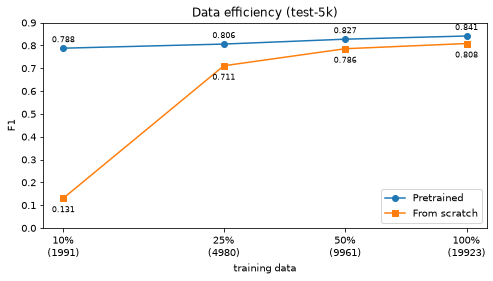

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
for m, mk, dy in [("Pretrained", "o-", 6), ("From scratch", "s-", -14)]:
    d = exp3[exp3.model == m].sort_values("n_train")
    ax.plot(d.n_train, d.f1, mk, label=m)
    for _, rr in d.iterrows():
        ax.annotate(f"{rr.f1:.3f}", (rr.n_train, rr.f1), textcoords="offset points", xytext=(0, dy), ha="center", fontsize=8)
ax.set_xscale("log")
ax.xaxis.set_minor_locator(plt.NullLocator())          # bỏ minor tick của thang log để nhãn không chồng nhau
ax.set_xticks(sorted(exp3.n_train.unique()), [f"{int(f * 100)}%\n({n})" for f, n in zip(FRACTIONS, sorted(exp3.n_train.unique()))])
ax.set(title="Data efficiency (test-5k)", xlabel="training data", ylabel="F1", ylim=(0, 0.9))
ax.legend()
plt.tight_layout()
plt.savefig("data_efficiency.png", dpi=120)
plt.show()

**Nhận xét Experiment 3** (F1 trên test-5k cố định)

| Training data | 10% | 25% | 50% | 100% |
|---|---|---|---|---|
| Pretrained | 0.788 | 0.806 | 0.827 | 0.841 |
| From scratch | 0.131 | 0.711 | 0.786 | 0.808 |
| Chênh lệch | 65.7 | 9.5 | 4.2 | 3.3 |

- Đi từ 100% xuống 10% dữ liệu, pretrained chỉ giảm 5.3 điểm, còn from scratch giảm 67.7 điểm.
- Ở 10%, model from scratch gần như đoán toàn bộ là negative (recall 0.07). Validation loss 0.685 gần bằng $\ln 2 = 0.693$, tức là chưa học được gì.
- Nhìn cả đường cong, khoảng cách giữa hai model tăng dần khi data giảm. Pretrained với 10% dữ liệu (0.788) đã ngang from scratch với 50% (0.786), tức cần ít dữ liệu hơn khoảng 5 lần.
- Lưu ý: ở 10%, model chỉ có 126 bước update (2 epoch). Model from scratch sụp đổ một phần vì số bước quá ít, nhưng xu hướng vẫn rõ ở 25% và 50%. Kết quả đúng với prediction 3.

## 5. Experiment 4 - Maximum sequence length

Pretrained fine-tuning trên 25% train (để giới hạn thời gian chạy trên CPU), max_length ∈ {64, 128, 256}, đánh giá test-5k với cùng max_length. Attention memory = batch 32 × 4 head × 4 layer × T² × 4 byte.

In [8]:
len_runs = {128: RUNS["Pretrained 25%"]}
for L in [64, 256]:
    len_runs[L] = run(f"Pretrained 25% L={L}", "exp4_length", pretrained=True, frac=0.25, L=L)
lengths_te = np.array([len(x) for x in tok([txt_te[i] for i in sub])["input_ids"]])
exp4 = pd.DataFrame([{"max length": L, "% review không bị cắt": 100 * (lengths_te <= L).mean(),
                      "accuracy": r["sub_accuracy"], "f1": r["sub_f1"], "train_time_s": r["train_time_s"],
                      "s/epoch": r["hist"].epoch_time_s.mean(),
                      "attention memory (MB)": BATCH * 4 * 4 * L * L * 4 / 2**20} for L, r in sorted(len_runs.items())]).set_index("max length")
for L, rr in exp4.iterrows():
    for k, v in rr.items():
        log("exp4_length", "Pretrained 25%", f"L={L}", "test_sub", k, v)
exp4.round(3)

Loading weights:   0%|          | 0/71 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: google/bert_uncased_L-4_H-256_A-4
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Pretrained 25% L=64: 4980 review train, L = 64


  epoch 1: train_loss 0.6251 val_loss 0.5242 val_acc 0.7414 (169 s)


  epoch 2: train_loss 0.4756 val_loss 0.5063 val_acc 0.7537 (168 s)


Loading weights:   0%|          | 0/71 [00:00<?, ?it/s]

... (2 outputs left out)

  epoch 1: train_loss 0.5257 val_loss 0.3564 val_acc 0.8448 (770 s)


  epoch 2: train_loss 0.3185 val_loss 0.3419 val_acc 0.8524 (756 s)


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (543 > 512). Running this sequence through the model will result in indexing errors


,% review không bị cắt,accuracy,f1,train_time_s,s/epoch,attention memory (MB)
max length,,,,,,
64,2.04,0.758,0.756,336.221,168.086,8.0
128,12.88,0.815,0.806,678.408,339.177,32.0
256,60.24,0.856,0.853,1526.859,763.411,128.0


**Nhận xét Experiment 4** (pretrained, 25% data, test-5k)

| Max length | % review không bị cắt | F1 | s/epoch | Attention memory |
|---|---|---|---|---|
| 64 | 2.0 | 0.756 | 168 | 8 MB |
| 128 | 12.9 | 0.806 | 339 | 32 MB |
| 256 | 60.2 | **0.853** | 763 | 128 MB |

- **Attention memory** là số tính theo công thức batch × head × layer × $T^2$ × 4 byte, không phải số đo thực tế. $T$ tăng 2 lần thì bộ nhớ tăng 4 lần, đúng với $O(T^2)$ ở LAB 06 - 07.
- Thời gian chỉ tăng 2 - 2.25 lần vì ở $T \le 256$, FFN và các projection (tỉ lệ với $T$) vẫn chiếm phần lớn tính toán.
- Trên IMDb, tăng length giúp nhiều (+9.7 F1 từ 64 lên 256). Review dài (median 221 token), nên ở 128 chỉ 12.9% review còn nguyên và phần kết luận ở cuối review thường bị cắt mất. Với 25% data, $T = 256$ còn vượt cả 100% data ở $T = 128$ (0.843).
- **Tăng length có luôn tốt hơn?** Không. Lợi ích phụ thuộc vào độ dài văn bản. Với câu ngắn như SST-2, tăng $T$ chỉ tốn thêm chi phí. Từ 256 lên 512, số review được giữ nguyên chỉ tăng thêm 26.6%, trong khi bộ nhớ attention tăng 4 lần.

## 6. Experiment 5 - Domain shift

Train trên IMDb (review phim dài), test trên: IMDb test (in-domain), SST-2 (câu ngắn về phim), Amazon (review sản phẩm), Yelp (review nhà hàng). Dữ liệu ngoài domain được tải sẵn vào `../hf_models/domain_data` (2,000 mẫu cân bằng mỗi tập, SST-2 dùng toàn bộ 872 câu validation).

In [9]:
DOMAIN_DIR = os.path.join(os.environ["HF_HOME"], "domain_data")
domains = {"IMDb (in-domain)": (txt_te, y_te)}
for name, f in [("SST-2 (phim, câu ngắn)", "sst2"), ("Amazon (sản phẩm)", "amazon"), ("Yelp (nhà hàng)", "yelp")]:
    d = pd.read_parquet(os.path.join(DOMAIN_DIR, f + ".parquet"))
    if QUICK:
        d = d.head(200)
    domains[name] = (d.text.tolist(), d.label.values)
dom_rows = []
for dname, (texts, y) in domains.items():
    for r in (r_pre, r_scr):
        logits = r["logits"] if dname.startswith("IMDb") else predict_logits(r["model"], *encode(tok, texts, MAX_LEN))
        m = metrics(y, logits.argmax(1))
        dom_rows.append({"domain": dname, "model": r["name"], "n": len(y), **m})
        for k, v in m.items():
            log("exp5_domain", r["name"], dname, "test", k, v)
dom = pd.DataFrame(dom_rows)
dom.pivot(index="domain", columns="model", values=["accuracy", "f1"]).reindex(list(domains)).round(4)

accuracy                                  f1  \
model                  From scratch Pretrained (fine-tune) From scratch   
domain                                                                    
IMDb (in-domain)             0.8153                 0.8424       0.8142   
SST-2 (phim, câu ngắn)       0.7362                 0.7775       0.7268   
Amazon (sản phẩm)            0.7775                 0.8200       0.7898   
Yelp (nhà hàng)              0.7605                 0.8200       0.7646   

                                               
model                  Pretrained (fine-tune)  
domain                                         
IMDb (in-domain)                       0.8430  
SST-2 (phim, câu ngắn)                 0.7996  
Amazon (sản phẩm)                      0.8307  
Yelp (nhà hàng)                        0.8225

**Nhận xét Experiment 5** (train trên IMDb, F1)

| Domain | Pretrained | Giảm | From scratch | Giảm |
|---|---|---|---|---|
| IMDb (in-domain) | 0.843 | | 0.814 | |
| SST-2 (phim, câu ngắn) | 0.800 | -4.3 | 0.727 | -8.7 |
| Amazon (sản phẩm) | 0.831 | -1.2 | 0.790 | -2.4 |
| Yelp (nhà hàng) | 0.823 | -2.1 | 0.765 | -5.0 |

- F1 của cả hai model đều giảm trên mọi domain khác. Pretrained không có nghĩa là "hiểu mọi domain", vì classifier chỉ được fine-tune trên review phim dài.
- Pretrained giảm ít hơn from scratch khoảng một nửa. Biểu diễn học từ văn bản tổng quát chuyển giao sang domain khác tốt hơn.
- SST-2 cũng là review phim nhưng lại giảm nhiều nhất, vì khác về hình thức: một câu ngắn thay vì review dài. Domain shift gồm cả chủ đề lẫn style.
- Amazon và Yelp có 2,000 mẫu, SST-2 có 872 mẫu, nên sai số khoảng ±1.8 - 2.7 điểm. Các chênh lệch nhỏ (ví dụ Amazon -1.2) cần đọc thận trọng.

## 7. Evaluation trên toàn bộ test

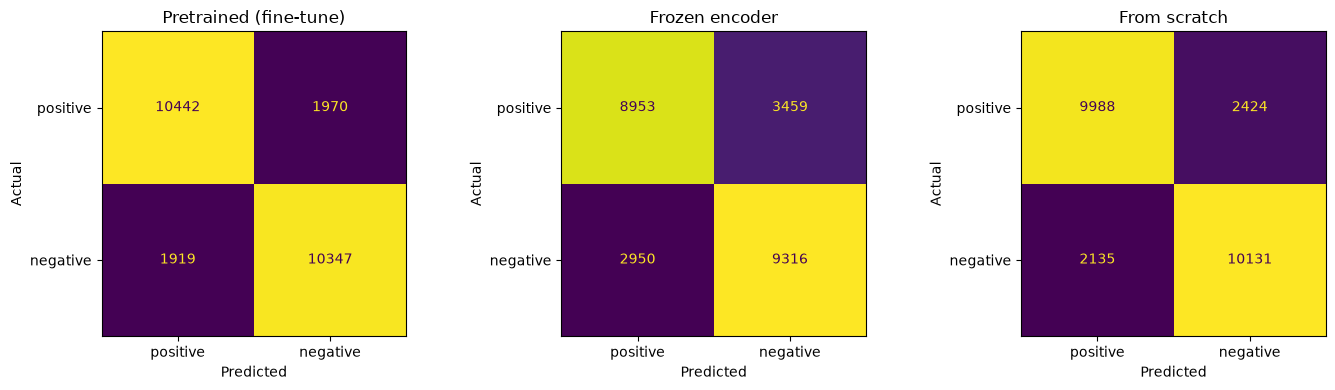

,accuracy,precision,recall,f1
model,,,,
Pretrained (fine-tune),0.8424,0.8448,0.8413,0.8430
Frozen encoder,0.7403,0.7522,0.7213,0.7364
From scratch,0.8153,0.8239,0.8047,0.8142


In [10]:
final = [("Pretrained (fine-tune)", r_pre["logits"]), ("Frozen encoder", frozen_logits), ("From scratch", r_scr["logits"])]
rows = []
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, logits) in zip(axes, final):
    pred = logits.argmax(1)
    rows.append({"model": name, **metrics(y_te, pred)})
    cm = confusion_matrix(y_te, pred, labels=[1, 0])
    ConfusionMatrixDisplay(cm, display_labels=["positive", "negative"]).plot(ax=ax, colorbar=False, values_format="d")
    ax.set(title=name, xlabel="Predicted", ylabel="Actual")
    for k, v in zip(["TP", "FN", "FP", "TN"], cm.ravel()):
        log("evaluation", name, "confusion_matrix", "test", k, v)
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=120)
plt.show()
pd.DataFrame(rows).set_index("model").round(4)

## 8. Confidence analysis

probabilities = softmax(logits), confidence = max probability. Nhóm: high ≥ 0.9, medium 0.7 - 0.9, low < 0.7.

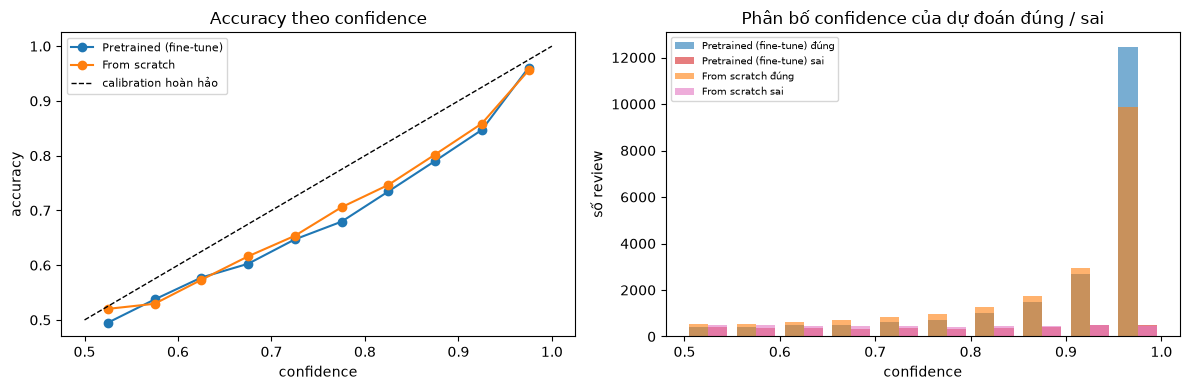

n  accuracy  mean_confidence  \
                       grp                                                  
Pretrained (fine-tune) low (<0.7)         3244    0.5539           0.6016   
                       medium (0.7-0.9)   5298    0.7269           0.8149   
                       high (≥0.9)       16136    0.9383           0.9727   
From scratch           low (<0.7)         4307    0.5616           0.6031   
                       medium (0.7-0.9)   6597    0.7384           0.8123   
                       high (≥0.9)       13774    0.9314           0.9685   

                                           % mẫu  
                       grp                        
Pretrained (fine-tune) low (<0.7)        13.1453  
                       medium (0.7-0.9)  21.4685  
                       high (≥0.9)       65.3862  
From scratch           low (<0.7)        17.4528  
                       medium (0.7-0.9)  26.7323  
                       high (≥0.9)       55.8149

In [11]:
def conf_table(logits, y):
    p = torch.tensor(logits).softmax(1).numpy()
    conf, pred = p.max(1), p.argmax(1)
    grp = pd.cut(conf, [0.5, 0.7, 0.9, 1.0001], labels=["low (<0.7)", "medium (0.7-0.9)", "high (≥0.9)"], include_lowest=True)
    t = pd.DataFrame({"conf": conf, "correct": pred == y, "grp": grp}).groupby("grp", observed=False).agg(
        n=("correct", "size"), accuracy=("correct", "mean"), mean_confidence=("conf", "mean"))
    t["% mẫu"] = 100 * t.n / t.n.sum()
    return t, conf, pred == y

conf_rows = {}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for r, c in [(r_pre, "tab:blue"), (r_scr, "tab:orange")]:
    t, conf, corr = conf_table(r["logits"], y_te)
    conf_rows[r["name"]] = t
    for g, rr in t.iterrows():
        for k in ["n", "accuracy", "mean_confidence", "% mẫu"]:
            log("confidence", r["name"], g, "test", k, rr[k])
    bins = np.linspace(0.5, 1.0, 11)
    b = np.digitize(conf, bins[1:-1])
    acc = [corr[b == i].mean() if (b == i).any() else np.nan for i in range(10)]
    axes[0].plot((bins[:-1] + bins[1:]) / 2, acc, "o-", color=c, label=r["name"])
    axes[1].hist([conf[corr], conf[~corr]], bins=bins, label=[f"{r['name']} đúng", f"{r['name']} sai"],
                 alpha=0.6, color=[c, "tab:red" if c == "tab:blue" else "tab:pink"])
axes[0].plot([0.5, 1], [0.5, 1], "k--", lw=1, label="calibration hoàn hảo")
axes[0].set(title="Accuracy theo confidence", xlabel="confidence", ylabel="accuracy")
axes[0].legend(fontsize=8)
axes[1].set(title="Phân bố confidence của dự đoán đúng / sai", xlabel="confidence", ylabel="số review")
axes[1].legend(fontsize=7)
plt.tight_layout()
plt.savefig("confidence_analysis.png", dpi=120)
plt.show()
pd.concat(conf_rows, axis=0).round(4)

**Nhận xét confidence**

- Accuracy tăng theo confidence: low 0.55, medium 0.73, high 0.94. Vậy confidence có mang thông tin về độ đúng.
- Tuy vậy, đường calibration nằm dưới đường chéo. Nhóm high có mean confidence 0.973 nhưng accuracy chỉ 0.938, tức model tự tin hơn mức đúng thực tế.
- Khoảng 996 trên 3,889 lỗi (25.6%) có confidence ≥ 0.9. **Confidence cao không đảm bảo prediction đúng.**
- Nhóm low (< 0.7) có accuracy 0.55, gần đoán ngẫu nhiên. Đây là nhóm nên chuyển cho người kiểm tra.
- Model from scratch có cùng xu hướng, nhưng ít dự đoán high hơn (55.8% so với 65.4%).

## 9. Application

In [12]:
APP = ["I really enjoyed this movie.", "I did not like this movie at all.",
       "I thought this movie would be bad, but it was actually excellent.",
       "The movie was okay, not great but not terrible either.",
       "Oh great, another two hours of my life I will never get back."]
app_rows = []
for t in APP:
    row = {"text": t}
    for r in (r_pre, r_scr):
        p = torch.tensor(predict_logits(r["model"], *encode(tok, [t], MAX_LEN))).softmax(1)[0, 1].item()
        row[f"P(pos) {r['name']}"] = p
        log("application", r["name"], t, "-", "p_pos", p)
    app_rows.append(row)
pd.DataFrame(app_rows).set_index("text").round(3)

,P(pos) Pretrained (fine-tune),P(pos) From scratch
text,,
I really enjoyed this movie.,0.994,0.999
I did not like this movie at all.,0.334,0.002
"I thought this movie would be bad, but it was actually excellent.",0.904,0.099
"The movie was okay, not great but not terrible either.",0.019,0.000
"Oh great, another two hours of my life I will never get back.",0.990,0.961


## 10. Error analysis (Pretrained fine-tune)

In [13]:
p_pre = torch.tensor(r_pre["logits"]).softmax(1).numpy()
n_tok = np.array([len(x) for x in tok(txt_te)["input_ids"]])
ea = test_df.assign(p_pos=p_pre[:, 1], pred=p_pre.argmax(1), conf=p_pre.max(1), n_tokens=n_tok,
                    p_scratch=torch.tensor(r_scr["logits"]).softmax(1).numpy()[:, 1])
ea["correct"] = ea.pred == ea.label
print(f"Tỉ lệ lỗi: {100 * (~ea.correct).mean():.1f}% | review > {MAX_LEN} token: {100 * (~ea.correct[ea.n_tokens > MAX_LEN]).mean():.1f}% "
      f"| ≤ {MAX_LEN} token: {100 * (~ea.correct[ea.n_tokens <= MAX_LEN]).mean():.1f}%")
short = ea[ea.n_tokens.between(20, 160)]
fp = short[(short.label == 0) & (short.pred == 1)].sort_values("conf", ascending=False).head(4)
fn = short[(short.label == 1) & (short.pred == 0)].sort_values("conf", ascending=False).head(4)
for title, d in [("FALSE POSITIVE", fp), ("FALSE NEGATIVE", fn)]:
    print(f"\n===== {title} =====")
    for i, rr in d.iterrows():
        print(f"#{i} true={LABEL_NAMES[rr.label]} P(pos)={rr.p_pos:.3f} conf={rr.conf:.3f} scratch P(pos)={rr.p_scratch:.3f} tokens={rr.n_tokens}\n   {rr.text[:500]}")

Tỉ lệ lỗi: 15.8% | review > 128 token: 16.7% | ≤ 128 token: 9.5%

===== FALSE POSITIVE =====
#4020 true=negative P(pos)=0.997 conf=0.997 scratch P(pos)=0.999 tokens=73
   This is definitely one of the best Kung fu movies in the history of Cinema. The screenplay is really well done (which is not often the case for this type of movies) and you can see that Chuck (in one of his first role)is a great actor. The final fight with the sherif deputy in the bullring is a masterpiece!
#3469 true=negative P(pos)=0.996 conf=0.996 scratch P(pos)=0.998 tokens=97
   This film has the language, the style and the attitude down ... plus greats rides from Occy (a world champ) and the great Jerry Lopez. John Philbin as Turtle has the surf pidgin down, and the surfing scenes are still the best ever. A true classic that can be seen many times. Nia Peeples is a babe, and Laird Hamilton shows the early stuff that has made him the world's number one extreme surfer.
#11859 true=negative P(pos)=0.996 conf=0.996 

**Nhận xét lỗi** (chi tiết trong `error_analysis.md`)

- Tỉ lệ lỗi chung là 15.8%: 16.7% ở review dài hơn 128 token, 9.5% ở review ngắn. Truncation là một nguyên nhân rõ, vì model chỉ đọc 128 token đầu.
- Ở các lỗi tự tin nhất (confidence > 0.99), model from scratch cũng sai cùng chiều. Vậy lỗi nằm ở dữ liệu và cách viết chứ không riêng ở pretrained model.
- Nhiều mẫu có nhãn đáng ngờ. Ví dụ #11859 viết "pure genius ... 9.5/10" nhưng có nhãn negative. Một số mẫu khác dùng sarcasm hoặc khen chê lẫn lộn.

## 11. Lưu kết quả

In [14]:
for k, v in repro.items():
    log("reproducibility", "-", k, "-", "value", str(v))
if not QUICK:
    pd.DataFrame(RESULTS).to_csv("results.csv", index=False)
print(len(RESULTS), "dòng" + ("" if QUICK else " đã ghi vào results.csv"))

311 dòng đã ghi vào results.csv
